In [1]:
from src.parametric_estimation import ParametricEstimation
from src.data_generator import DataGenerator
from src.motivating_example import UtoM
import numpy as np

import matplotlib.pyplot as plt

from scipy.stats import logistic
from sklearn.metrics import root_mean_squared_error

from joblib import Parallel, delayed

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In [2]:
import torch
import numpy as np
from src.r_funcs import r_ampute
from src.converter import Converter

class AmputeMAR:

    def __init__(self, n:int, d:int, n_pat:int, seed:int):

        if n_pat < 1:
            raise ValueError('Number of patterns should be at least 1')

        self.n = n
        self.d = d
        self.n_pat = n_pat # number of patterns
        self.seeds = np.random.SeedSequence(seed).spawn(3)
        self.rng, self.rng_amp, self.rng_eps = [np.random.default_rng(s) for s in self.seeds]
        self.seed_amp = int(self.rng_amp.integers(1, 2**31 - 1))
        self.seed_eps = int(self.rng_eps.integers(1, 2**31 - 1))
        self.patterns = self.sample_patterns()

        converter = Converter()
        self.to_r = converter.to_r
        self.to_python = converter.to_python


    def sample_patterns(self) -> np.array:
        """Sample incomplete missingness patterns once (1 = observed, 0 = missing).
        Last column is always observed; all-ones rows are excluded."""
        while True:
            if self.n_pat is None:
                self.n_pat = int(self.rng.integers(3, max(round(n / 100), 3) + 1))

            patterns = self.rng.integers(0, 2, size=(self.n_pat, d - 1))
            # last column is always observed
            patterns = np.hstack([patterns, np.ones((self.n_pat, 1), dtype=int)])
            incomplete = patterns[~patterns.all(axis=1)]
            if incomplete.shape[0] > 0:
                return incomplete


    def ampute(self, X:torch.tensor, prop:float = None, miss_mech:str = 'MAR', miss_type: str = 'RIGHT', weights = None) -> tuple:
        """
        Parameters
        ----------
        X : torch.Tensor, shape (n, d)
            Complete data.

        prop : float, optional
            Proportion of cases with missing values (so 1 - prop stay complete).
            Default: n_pats / (n_pats + 1), i.e. the complete cases are as
            frequent as each incomplete pattern.

        miss_type : str
            RIGHT:
            ...

        Returns
        -------
        X_NA : torch.Tensor
            Data with NaN values.
        M : torch.Tensor
            Observation mask: 1 = observed, 0 = missing.
        """

        n_pats = len(self.patterns)

        if prop is None:
            prop = n_pats / (n_pats + 1)

        if n_pats > 0:
            result = r_ampute(
                self.to_r(X),
                patterns=self.to_r(self.patterns),
                prop=prop,              # freq defaults to equal across patterns
                mech=miss_mech,
                bycases=True,
                type=self.to_r(miss_type),
                weights=self.to_r(weights),
                seed=self.seed_amp
            )
            # amp = amp.to_numpy() if hasattr(amp, "to_numpy") else np.asarray(amp)
            X_NA = torch.tensor(self.to_python(result)['amp'], device=X.device, dtype=X.dtype)   # (n, d)

        M = ~torch.isnan(X_NA)

        return X_NA, M
    

    def ampute_eps(self, X:torch.tensor, c0:float = 0.01, eps:float = None):
        # mask1: complete case
        complete = self.rng_eps.random(self.n) < c0
        # mask2: mnar
        mnar = ~complete & (self.rng_eps.random(self.n) < eps / (1 - c0))   # gives eps*n MNAR rows on average
        # mask3: mar
        mar = ~complete & ~mnar

        X_NA = X.clone().detach().cpu().numpy()
        rpatterns = self.to_r(self.patterns)
        for mask, mech, s in zip([mnar, mar], ['MNAR', 'MAR'], [self.seed_eps, self.seed_eps+1]):
            if mask.sum() == 0:
                continue
            result = r_ampute(
                self.to_r(X_NA[mask]),
                patterns = rpatterns,
                mech = mech,
                seed = s
                )
            X_NA[mask] = self.to_python(result)['amp']

        X_NA = torch.tensor(X_NA, device=X.device, dtype=X.dtype)

        M = (~torch.isnan(X_NA)).int()

        return X_NA, M, complete, mnar, mar

In [3]:
class MissingDataGenerator(DataGenerator, AmputeMAR, UtoM):

    def __init__(self, 
                 n:int, d:int,
                 n_pat:int, seed:int,
                 distr = "normal", mu = None, sigma = None, pi = None, alpha = 0.7, c = 0.01, df = None, device = "cpu", dtype=torch.float64):
        DataGenerator.__init__(self, distr=distr, mu=mu, sigma=sigma, pi=pi, alpha=alpha, c=c, df=df, device=device, dtype=dtype)
        AmputeMAR.__init__(self, n=n, d=d, n_pat=n_pat, seed=seed)
        UtoM.__init__(self, d=d)
        self.n = n
        self.d = d

    def get_X(self):
        return self.sample_truth(n=self.n, d=self.d)

    def get_M_ampute_eps(self, X, eps):
        Xmis, M, _, _, _ = self.ampute_eps(X, eps=eps)
        return Xmis, M

    def get_M_eps_mar(self, X, eps):
        u1 = self.x_to_u(X[:,0])
        u2 = self.x_to_u(X[:,1])
        M = self.get_M(missing_type='contaminated_mar', u1=u1, u2=u2, eps=eps)
        return M

In [4]:
n = 2000
d = 20
n_pat = 3
k_range = (0,20)
eps = 1e-2
fast = True # only Xtrain
var_index = 0
p = 0.1

In [5]:
# Specify data model
mdg = MissingDataGenerator(n=n, d=d, n_pat=n_pat, seed=1, distr='logistic') # the patterns is sampled once in the init

In [6]:
# Single job
def job(
        # n:int = None, # sample size
        # d:int = None, # data dimension
        # patterns = None, # arg of mice:ampute
        # prop:float = None, # arg of mice::ampute
        eps: float = None, # clamping scale
        fast: bool = None, # if fast, use fast algorithm of nmm
        var_index:int = None, # which variable
        p:float = None, # quantile
        ):
    X = mdg.get_X()
    _, M = mdg.ampute(X)
    pe = ParametricEstimation(X=X, M=M)
    ps_gmm = pe._propensity_score_Xc(method='gmm', eps=eps)
    ps_nmm = pe._propensity_score_Xc(method='nmm', eps=eps, fast=fast)
    qs = (
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_gmm).item(), 
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_nmm).item(),
        pe.quantile_by_generation(var_index=var_index, p=p).item(),
    )
    ms = np.stack(
        [
            pe.mean_by_ipw(propensity_score=ps_gmm), 
            pe.mean_by_ipw(propensity_score=ps_nmm),
            pe.mean_by_generation(),
        ],
        axis=0
    )
    return qs, ms

In [7]:
B = 1 # CHANGE

results = Parallel(n_jobs=15)(
    delayed(job)(
        eps=eps,
        fast=fast,
        var_index=var_index,
        p=p,
    )
    for _ in range(B)
)

Fast method only supports Xtrain


In [8]:
quantile_results = np.stack([q for q, _ in results])

mean_results = np.stack([
    np.sqrt(np.mean(np.square(m), axis=-1))
    for _, m in results
])

results = (quantile_results, mean_results)

# np.save('results/quantile_results.npy', quantile_results)
# np.save('results/mean_results.npy', mean_results)

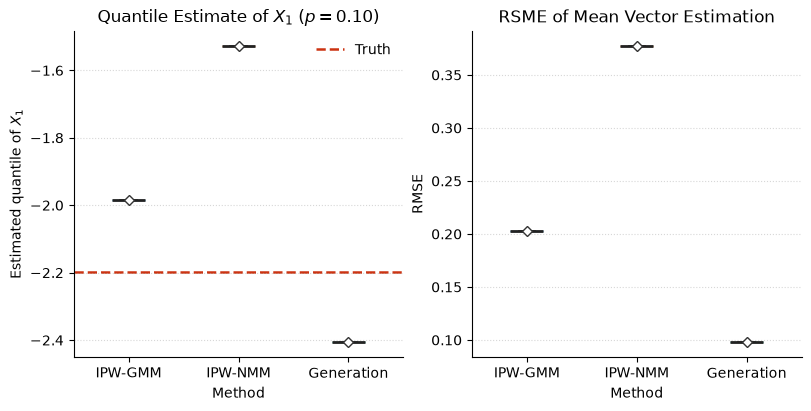

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

for ax, result in zip(axes, results):

    bp = ax.boxplot(
        result,
        tick_labels=['IPW-GMM', 'IPW-NMM', 'Generation'],
        patch_artist=True,
        widths=0.3,
        showmeans=True,
        meanprops=dict(
            marker="D",
            markerfacecolor="white",
            markeredgecolor="#333333",
            markersize=5,
        ),
        medianprops=dict(color="#222222", linewidth=2),
        whiskerprops=dict(color="#555555", linewidth=1.2),
        capprops=dict(color="#555555", linewidth=1.2),
        flierprops=dict(
            marker="o",
            markersize=4,
            markerfacecolor="#999999",
            markeredgecolor="none",
            alpha=0.6,
        ),
    )

    # Colorblind-friendly palette
    colors = ["#0072B2", "#D55E00", "#009E73"]
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.75)
        box.set_edgecolor(color)

    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Reference quantile
y_ref = logistic.ppf(p)
axes[0].axhline(
    y=y_ref,
    color="#CC3311",
    linestyle="--",
    linewidth=1.8,
    label="Truth",
    zorder=0,
)

axes[0].set(
    title=fr"Quantile Estimate of $X_1$ ($p={p:.2f}$)",
    xlabel="Method",
    ylabel=r"Estimated quantile of $X_1$",
)

axes[1].set(
    title=fr"RSME of Mean Vector Estimation",
    xlabel="Method",
    ylabel=r"RMSE",
)

axes[0].legend(frameon=False, loc="best")

plt.savefig(f'results/pe_quantile_mean_{n_pat}_patterns_{B}_B.png',dpi=300,
    bbox_inches="tight",)

plt.show()
